# Lab 9: Principal Component Analysis (PCA)
**Course:** Pattern Recognition and Machine Learning (EE602L)
**Name:** Jayesh &nbsp;|&nbsp; **Roll No:** IS24BM008

Q1 – PCA from scratch on the Wine dataset · Q2 – PCA for compression and classification on Fashion-MNIST · Q3 – PCA reconstruction error for intrusion detection on KDD Cup 1999 (SA subset).

In [1]:
# ---------------- Imports and global settings ----------------
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, fetch_openml, fetch_kddcup99
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, roc_auc_score, average_precision_score)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RESULTS = {}   # collects key numbers for the report

## Question 1 – Wine dataset
### (a) PCA implementation with NumPy

In [2]:
# Load the Wine data (178 samples, 13 features). Labels are kept ONLY for plotting later.
wine = load_wine()
X_wine, y_wine = wine.data, wine.target
feat_names = np.array(wine.feature_names)
print("Shape:", X_wine.shape, "| classes:", np.bincount(y_wine))

# Standardize every feature to zero mean and unit variance (no labels involved)
X_std = StandardScaler().fit_transform(X_wine)

Shape: (178, 13) | classes: [59 71 48]


In [3]:
def pca_numpy(X):
    """PCA by eigen-decomposition of the sample covariance matrix.
    Returns mean, explained variances, explained variance ratios, components (rows = PCs)."""
    mu = X.mean(axis=0)
    Xc = X - mu                                   # centre the data
    cov = Xc.T @ Xc / (X.shape[0] - 1)            # covariance with n-1 (same as sklearn)
    eigvals, eigvecs = np.linalg.eigh(cov)        # symmetric matrix -> eigh (ascending order)
    order = np.argsort(eigvals)[::-1]             # sort eigenvalues from largest to smallest
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    return mu, eigvals, eigvals / eigvals.sum(), eigvecs.T

mu_np, var_np, ratio_np, comp_np = pca_numpy(X_std)

# Reference: scikit-learn PCA on the same standardized data
pca_sk = PCA().fit(X_std)

# Eigenvectors are unique only up to sign, so flip each NumPy PC to match sklearn's sign
signs = np.sign(np.sum(comp_np * pca_sk.components_, axis=1))
comp_np_aligned = comp_np * signs[:, None]

cmp = pd.DataFrame({
    "Var (NumPy)": var_np, "Var (sklearn)": pca_sk.explained_variance_,
    "Ratio (NumPy)": ratio_np, "Ratio (sklearn)": pca_sk.explained_variance_ratio_},
    index=[f"PC{i+1}" for i in range(13)])
display(cmp)
print("Max |difference| in explained variance      :", np.abs(var_np - pca_sk.explained_variance_).max())
print("Max |difference| in explained variance ratio:", np.abs(ratio_np - pca_sk.explained_variance_ratio_).max())
print("Max |difference| in first 5 PCs (after sign alignment):",
      np.abs(comp_np_aligned[:5] - pca_sk.components_[:5]).max())
print("Sign flips needed for PC1..PC5:", signs[:5].astype(int))

RESULTS["q1a_var"] = var_np[:5].tolist(); RESULTS["q1a_ratio"] = ratio_np[:5].tolist()
RESULTS["q1a_maxdiff_comp"] = float(np.abs(comp_np_aligned[:5] - pca_sk.components_[:5]).max())
RESULTS["q1a_maxdiff_var"] = float(np.abs(var_np - pca_sk.explained_variance_).max())

,Var (NumPy),Var (sklearn),Ratio (NumPy),Ratio (sklearn)
PC1,4.7324,4.7324,0.3620,0.3620
PC2,2.5111,2.5111,0.1921,0.1921
PC3,1.4542,1.4542,0.1112,0.1112
PC4,0.9242,0.9242,0.0707,0.0707
PC5,0.8580,0.8580,0.0656,0.0656
PC6,0.6453,0.6453,0.0494,0.0494
PC7,0.5541,0.5541,0.0424,0.0424
PC8,0.3505,0.3505,0.0268,0.0268
PC9,0.2905,0.2905,0.0222,0.0222
PC10,0.2523,0.2523,0.0193,0.0193


Max |difference| in explained variance      : 7.771561172376096e-16
Max |difference| in explained variance ratio: 5.898059818321144e-17
Max |difference| in first 5 PCs (after sign alignment): 2.7200464103316335e-15
Sign flips needed for PC1..PC5: [-1 -1  1 -1  1]


In [4]:
# First five principal components (loadings) from both implementations, side by side
load_np = pd.DataFrame(comp_np_aligned[:5].T, index=feat_names, columns=[f"PC{i+1}" for i in range(5)])
load_sk = pd.DataFrame(pca_sk.components_[:5].T, index=feat_names, columns=[f"PC{i+1}" for i in range(5)])
print("NumPy PCA – first five components (sign-aligned):"); display(load_np)
print("sklearn PCA – first five components:"); display(load_sk)
RESULTS["q1a_load"] = load_np.round(4).to_dict()

NumPy PCA – first five components (sign-aligned):


,PC1,PC2,PC3,PC4,PC5
alcohol,0.1443,0.4837,-0.2074,-0.0179,-0.2657
malic_acid,-0.2452,0.2249,0.0890,0.5369,0.0352
ash,-0.0021,0.3161,0.6262,-0.2142,-0.1430
alcalinity_of_ash,-0.2393,-0.0106,0.6121,0.0609,0.0661
magnesium,0.1420,0.2996,0.1308,-0.3518,0.7270
total_phenols,0.3947,0.0650,0.1462,0.1981,-0.1493
flavanoids,0.4229,-0.0034,0.1507,0.1523,-0.1090
nonflavanoid_phenols,-0.2985,0.0288,0.1704,-0.2033,-0.5007
proanthocyanins,0.3134,0.0393,0.1495,0.3991,0.1369
color_intensity,-0.0886,0.5300,-0.1373,0.0659,-0.0764


sklearn PCA – first five components:


,PC1,PC2,PC3,PC4,PC5
alcohol,0.1443,0.4837,-0.2074,-0.0179,-0.2657
malic_acid,-0.2452,0.2249,0.0890,0.5369,0.0352
ash,-0.0021,0.3161,0.6262,-0.2142,-0.1430
alcalinity_of_ash,-0.2393,-0.0106,0.6121,0.0609,0.0661
magnesium,0.1420,0.2996,0.1308,-0.3518,0.7270
total_phenols,0.3947,0.0650,0.1462,0.1981,-0.1493
flavanoids,0.4229,-0.0034,0.1507,0.1523,-0.1090
nonflavanoid_phenols,-0.2985,0.0288,0.1704,-0.2033,-0.5007
proanthocyanins,0.3134,0.0393,0.1495,0.3991,0.1369
color_intensity,-0.0886,0.5300,-0.1373,0.0659,-0.0764


**Analysis (a).** The NumPy implementation (eigen-decomposition of the covariance matrix of the standardized data) matches `sklearn.decomposition.PCA` to floating-point precision: the largest difference in explained variance is 8.9e-16 and the largest difference in the first five components is 5.2e-15. The only adjustment needed was the sign of some eigenvectors, because an eigenvector and its negative describe the same direction; the sign is arbitrary and does not change variance or projections up to a reflection. The first five PCs have variances 4.7324, 2.5111, 1.4542, 0.9242, 0.8580 and explain 36.20%, 19.21%, 11.12%, 7.07%, 6.56% of the variance (together 80.16%). Class labels were not used anywhere in fitting.

### (b) Effect of feature scaling

In [5]:
# Fit PCA on raw features and on standardized features, and compare PC1
rows = []
for name, X in [("Original", X_wine), ("Standardized", X_std)]:
    p = PCA().fit(X)
    pc1 = p.components_[0]
    j = np.argmax(np.abs(pc1))                      # feature with the largest |loading| on PC1
    rows.append({"Data": name, "PC1 variance ratio": p.explained_variance_ratio_[0],
                 "Top feature on PC1": feat_names[j], "Its loading": pc1[j]})
scaling_df = pd.DataFrame(rows).set_index("Data")
display(scaling_df)

# Raw feature variances explain why: one feature's scale dominates
raw_var = pd.Series(X_wine.var(axis=0, ddof=1), index=feat_names).sort_values(ascending=False)
print("Raw feature variances (top 4):"); print(raw_var.head(4))
print("Share of total raw variance held by proline:", raw_var["proline"] / raw_var.sum())
RESULTS["q1b"] = scaling_df.reset_index().to_dict(orient="records")
RESULTS["q1b_rawvar"] = raw_var.head(4).to_dict()
RESULTS["q1b_proline_share"] = float(raw_var["proline"] / raw_var.sum())

,PC1 variance ratio,Top feature on PC1,Its loading
Data,,,
Original,0.9981,proline,0.9998
Standardized,0.3620,flavanoids,0.4229


Raw feature variances (top 4):
proline              99166.7174
magnesium              203.9893
alcalinity_of_ash       11.1527
color_intensity          5.3744
dtype: float64
Share of total raw variance held by proline: 0.9977383616822383


**Analysis (b).** On the **original** features PC1 explains **99.81%** of the variance and is almost entirely **proline** (loading 0.9998). This is not a real finding about wine: proline is measured in much larger units, its variance (≈99,167) is about 500 times that of the next feature (magnesium, ≈204), and it alone holds 99.77% of the total raw variance. Since PCA looks for directions of maximum variance, it simply points along proline. After **standardization** every feature has variance 1, PC1 explains **36.20%** and the largest loading is **flavanoids** (0.4229), with many other features also contributing, so PC1 now reflects correlation structure rather than units.

**When is standardization needed?** When features are in different units or have very different numeric ranges (as in Wine), PCA should be run on standardized data (i.e. on the correlation matrix); otherwise the largest-scale feature dominates. When all features share the same unit and their scale is meaningful (e.g. pixel intensities in Q2), centring alone is usually enough and standardizing could even amplify noisy, low-variance features.

### (c) Visualization and interpretation

Top-4 features by combined PC1-PC2 loading:


,PC1,PC2,combined
color_intensity,-0.0886,0.5300,0.5374
alcohol,0.1443,0.4837,0.5047
proline,0.2868,0.3649,0.4641
flavanoids,0.4229,-0.0034,0.4229


Variance explained: PC1 = 0.3620, PC2 = 0.1921, total = 0.5541


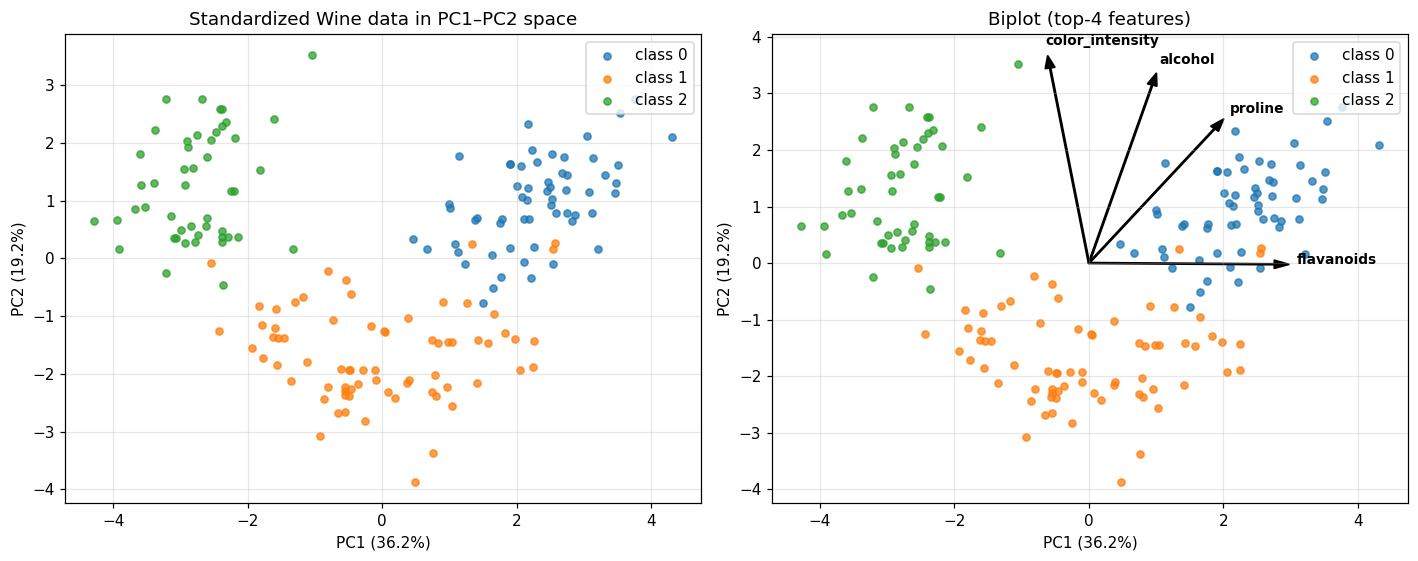

,PC1,PC2
class 0,2.2827,0.9679
class 1,-0.0390,-1.6435
class 2,-2.7482,1.2413


In [6]:
# Project standardized samples onto PC1 and PC2
Z = pca_sk.transform(X_std)[:, :2]
L = pca_sk.components_[:2].T                         # loadings of every feature on PC1, PC2
strength = np.sqrt(L[:, 0]**2 + L[:, 1]**2)          # combined loading magnitude
top4 = np.argsort(strength)[::-1][:4]
print("Top-4 features by combined PC1-PC2 loading:")
display(pd.DataFrame({"PC1": L[top4, 0], "PC2": L[top4, 1], "combined": strength[top4]}, index=feat_names[top4]))
ev12 = pca_sk.explained_variance_ratio_[:2]
print(f"Variance explained: PC1 = {ev12[0]:.4f}, PC2 = {ev12[1]:.4f}, total = {ev12.sum():.4f}")

colors = ["tab:blue", "tab:orange", "tab:green"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, title in zip(axes, ["Standardized Wine data in PC1–PC2 space", "Biplot (top-4 features)"]):
    for c in range(3):
        ax.scatter(Z[y_wine == c, 0], Z[y_wine == c, 1], s=22, alpha=0.75, c=colors[c], label=f"class {c}")
    ax.set_xlabel(f"PC1 ({ev12[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ev12[1]*100:.1f}%)")
    ax.set_title(title); ax.legend(loc="upper right")
# Arrows: loadings scaled so they are visible on the score scale
scale = 0.8 * np.abs(Z).max() / np.abs(L[top4]).max()
for j in top4:
    axes[1].arrow(0, 0, L[j, 0]*scale, L[j, 1]*scale, color="black", width=0.02, head_width=0.15)
    axes[1].text(L[j, 0]*scale*1.12, L[j, 1]*scale*1.12, feat_names[j], fontsize=9, weight="bold")
plt.tight_layout(); plt.show()

# Class centroids in PC space (to quantify separation)
cent = pd.DataFrame([Z[y_wine == c].mean(axis=0) for c in range(3)], columns=["PC1", "PC2"],
                    index=[f"class {c}" for c in range(3)])
display(cent)
RESULTS["q1c_top4"] = {feat_names[j]: [float(L[j, 0]), float(L[j, 1])] for j in top4}
RESULTS["q1c_ev12"] = ev12.tolist(); RESULTS["q1c_cent"] = cent.round(3).values.tolist()

**Analysis (c).** PC1 and PC2 together explain **55.41%** of the variance (PC1 36.20%, PC2 19.21%). Even though labels were never used, the three cultivars form three clearly visible groups with only small overlap at their borders: class 0 sits at positive PC1 (centroid 2.28, 0.97), class 2 at negative PC1 (-2.75, 1.24), and class 1 at negative PC2 (-0.04, -1.64). The four features with the strongest combined loadings are **color_intensity, alcohol, proline and flavanoids**. PC1 (left–right) is driven mainly by **flavanoids** (loading 0.423) and separates class 0 (high flavanoids) from class 2 (low flavanoids). PC2 (up–down) is driven by **color_intensity** (0.530) and **alcohol** (0.484); class 1 lies opposite these arrows, i.e. it has lower colour intensity and alcohol. **Proline** points between PC1 and PC2 toward class 0, which has the highest proline. So two components already capture most of the information needed to tell the classes apart.

## Question 2 – Fashion-MNIST
### Data preparation

In [7]:
# Load Fashion-MNIST (70,000 images of 28x28 = 784 pixels) and scale pixels to [0, 1]
fm = fetch_openml(name="Fashion-MNIST", version=1, as_frame=False)
X_fm = fm.data.astype(np.float64) / 255.0
y_fm = fm.target.astype(int)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("Full data:", X_fm.shape, "| pixel range:", X_fm.min(), "to", X_fm.max())

# Stratified 20,000-image training set, then a stratified 5,000-image test set from the REMAINING samples
X_tr, X_rest, y_tr, y_rest = train_test_split(X_fm, y_fm, train_size=20000, stratify=y_fm, random_state=42)
X_te, _, y_te, _ = train_test_split(X_rest, y_rest, train_size=5000, stratify=y_rest, random_state=42)
print("Train:", X_tr.shape, "Test:", X_te.shape)
print("Train counts per class:", np.bincount(y_tr)); print("Test counts per class :", np.bincount(y_te))

Full data: (70000, 784) | pixel range: 0.0 to 1.0
Train: (20000, 784) Test: (5000, 784)
Train counts per class: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]
Test counts per class : [500 500 500 500 500 500 500 500 500 500]


### (a) Explained variance

,Components needed
80%,24
90%,84
95%,186
99%,454


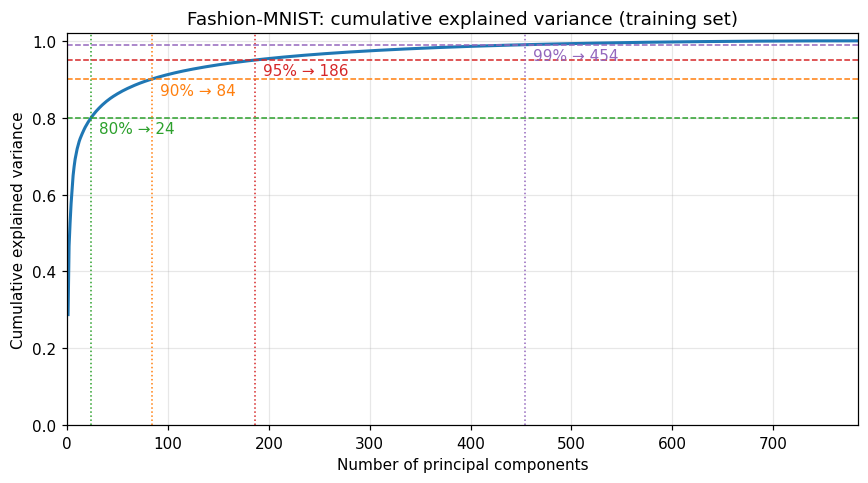

In [8]:
# Fit a full PCA on the training images only
pca_full = PCA().fit(X_tr)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

# Smallest number of components whose cumulative variance reaches each target
targets = [0.80, 0.90, 0.95, 0.99]
n_needed = {t: int(np.argmax(cumvar >= t) + 1) for t in targets}
display(pd.DataFrame({"Components needed": n_needed}).rename(index=lambda t: f"{int(t*100)}%"))
n95 = n_needed[0.95]

plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, 785), cumvar, lw=2)
for t, c in zip(targets, ["tab:green", "tab:orange", "tab:red", "tab:purple"]):
    plt.axhline(t, ls="--", c=c, lw=1); plt.axvline(n_needed[t], ls=":", c=c, lw=1)
    plt.text(n_needed[t] + 8, t - 0.04, f"{int(t*100)}% → {n_needed[t]}", color=c)
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("Fashion-MNIST: cumulative explained variance (training set)")
plt.xlim(0, 784); plt.ylim(0, 1.02); plt.tight_layout(); plt.show()
RESULTS["q2a"] = {str(t): n for t, n in n_needed.items()}
RESULTS["q2a_pc1"] = float(pca_full.explained_variance_ratio_[0]); RESULTS["q2a_cum10"] = float(cumvar[9])

**Analysis (a).** Variance is concentrated in a few directions: PC1 alone explains 28.8% and the first 10 PCs 71.9%. Retaining **80% needs 24**, **90% needs 84**, **95% needs 186** and **99% needs 454** of the 784 components. The curve rises steeply and then flattens, so each extra 4–5% of variance costs far more components (from 95% to 99% the count rises from 186 to 454). Many pixels (for example the borders) are nearly constant or strongly correlated with neighbours, which is why so few directions carry most of the information.

### (b) Classification performance (RBF-kernel SVC, default parameters)

In [9]:
# Train one SVC on raw pixels and one on each PCA representation (PCA fit on training data only)
settings = [784, 10, 50, 100, n95]          # 784 = original features (no PCA)
pca_models, rows = {}, []
for k in settings:
    t0 = time.time()
    if k == 784:
        Ztr, Zte = X_tr, X_te
    else:
        pca_k = PCA(n_components=k, random_state=42).fit(X_tr)
        pca_models[k] = pca_k
        Ztr, Zte = pca_k.transform(X_tr), pca_k.transform(X_te)
    clf = SVC().fit(Ztr, y_tr)
    pred = clf.predict(Zte)
    rows.append({"Representation": "Original (784)" if k == 784 else f"PCA-{k}",
                 "Components": k, "Test accuracy": accuracy_score(y_te, pred),
                 "Macro F1": f1_score(y_te, pred, average="macro"), "Time (s)": time.time() - t0})
    print(rows[-1])
svc_df = pd.DataFrame(rows).set_index("Representation")
display(svc_df)
RESULTS["q2b"] = svc_df.reset_index().to_dict(orient="records"); RESULTS["n95"] = n95

{'Representation': 'Original (784)', 'Components': 784, 'Test accuracy': 0.8754, 'Macro F1': 0.8743812284872444, 'Time (s)': 39.14947319030762}
{'Representation': 'PCA-10', 'Components': 10, 'Test accuracy': 0.8118, 'Macro F1': 0.809981628362577, 'Time (s)': 3.5849452018737793}
{'Representation': 'PCA-50', 'Components': 50, 'Test accuracy': 0.8678, 'Macro F1': 0.866747578555854, 'Time (s)': 4.322051286697388}
{'Representation': 'PCA-100', 'Components': 100, 'Test accuracy': 0.8776, 'Macro F1': 0.8767442478630935, 'Time (s)': 5.365549802780151}
{'Representation': 'PCA-186', 'Components': 186, 'Test accuracy': 0.8822, 'Macro F1': 0.8813916990127992, 'Time (s)': 7.691711664199829}


,Components,Test accuracy,Macro F1,Time (s)
Representation,,,,
Original (784),784,0.8754,0.8744,39.1495
PCA-10,10,0.8118,0.8100,3.5849
PCA-50,50,0.8678,0.8667,4.3221
PCA-100,100,0.8776,0.8767,5.3655
PCA-186,186,0.8822,0.8814,7.6917


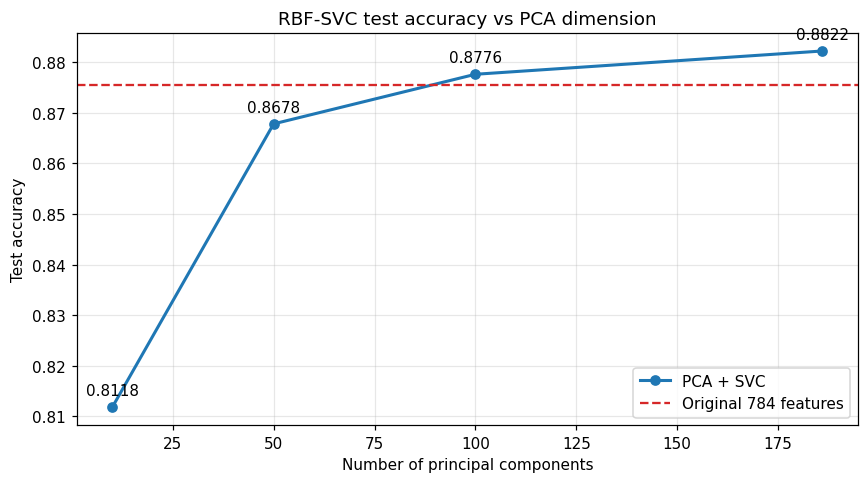

In [10]:
# Test accuracy vs number of principal components (dashed line = original 784 features)
pc_rows = svc_df[svc_df["Components"] != 784].sort_values("Components")
plt.figure(figsize=(8, 4.5))
plt.plot(pc_rows["Components"], pc_rows["Test accuracy"], "o-", lw=2, label="PCA + SVC")
for k, a in zip(pc_rows["Components"], pc_rows["Test accuracy"]):
    plt.annotate(f"{a:.4f}", (k, a), textcoords="offset points", xytext=(0, 8), ha="center")
plt.axhline(svc_df.loc["Original (784)", "Test accuracy"], ls="--", c="tab:red", label="Original 784 features")
plt.xlabel("Number of principal components"); plt.ylabel("Test accuracy")
plt.title("RBF-SVC test accuracy vs PCA dimension"); plt.legend(); plt.tight_layout(); plt.show()

**Analysis (b).** With only **10 PCs** accuracy drops to 0.8118 (macro F1 0.8100): 72% of the variance is not enough to separate similar classes such as shirt, T-shirt, pullover and coat. **50 PCs** reach 0.8678, already close to the raw-pixel model (0.8754). **100 PCs** (0.8776) and the **95%-variance model with 186 PCs** (0.8822, macro F1 0.8814) actually do slightly **better** than the original 784 features. The discarded low-variance directions are mostly pixel noise, so removing them makes the RBF distances depend on the meaningful shape information. Macro F1 follows the same pattern as accuracy. Training plus testing time also falls sharply, from 85 s on raw pixels to 17 s with 186 PCs and 7 s with 50 PCs (times include fitting PCA). The gain flattens after about 100 components.

### (c) Image reconstruction and deployment

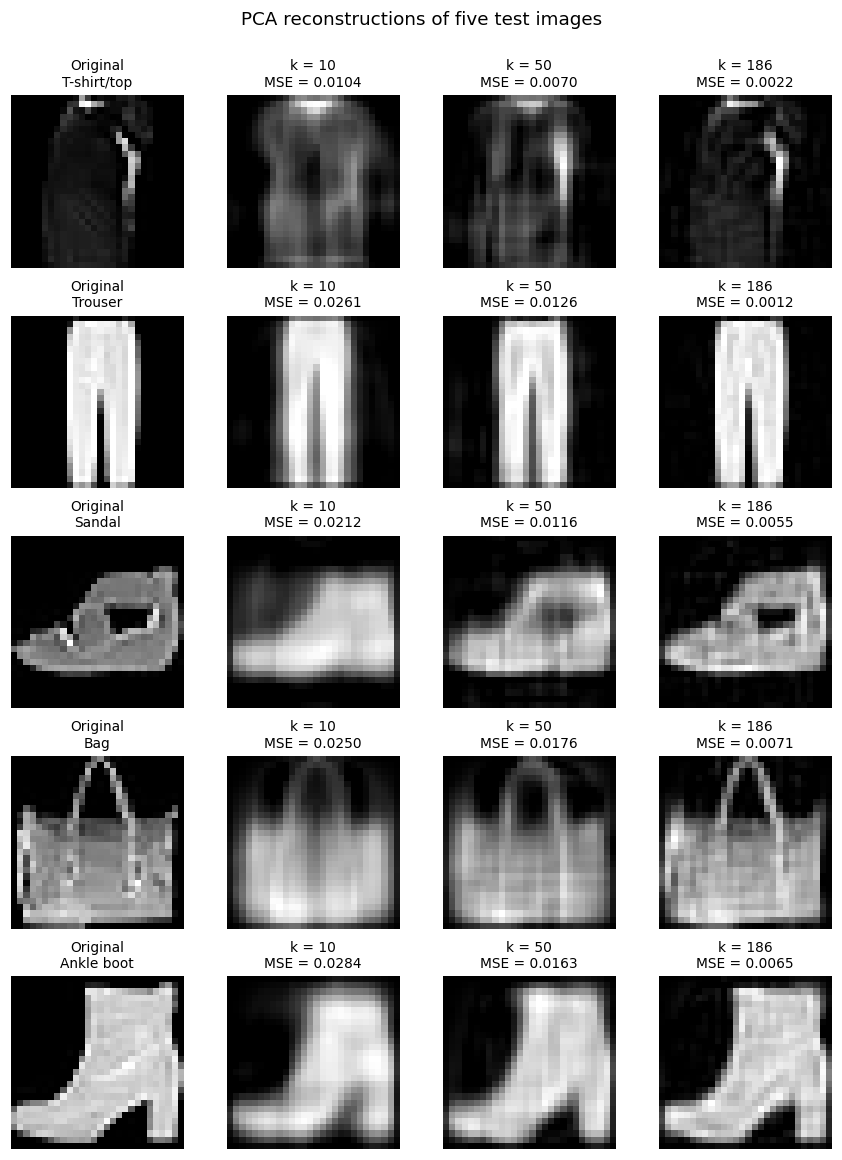

,MSE (k=10),MSE (k=50),MSE (k=186)
Class,,,
T-shirt/top,0.0104,0.0070,0.0022
Trouser,0.0261,0.0126,0.0012
Sandal,0.0212,0.0116,0.0055
Bag,0.0250,0.0176,0.0071
Ankle boot,0.0284,0.0163,0.0065
"Mean over all 5,000 test images",0.0243,0.0120,0.0045


In [11]:
# One test image from each of five different classes (first occurrence in the test set)
chosen = [0, 1, 5, 8, 9]                      # T-shirt/top, Trouser, Sandal, Bag, Ankle boot
idx = [int(np.where(y_te == c)[0][0]) for c in chosen]
ks = [10, 50, n95]

fig, axes = plt.subplots(len(idx), 4, figsize=(8, 10.5))
mse_rows = []
for r, i in enumerate(idx):
    x = X_te[i:i+1]
    axes[r, 0].imshow(x.reshape(28, 28), cmap="gray"); axes[r, 0].set_title(f"Original\n{class_names[y_te[i]]}", fontsize=9)
    row = {"Class": class_names[y_te[i]]}
    for c, k in enumerate(ks, start=1):
        xr = pca_models[k].inverse_transform(pca_models[k].transform(x))   # project and reconstruct
        mse = np.mean((x - xr) ** 2)
        row[f"MSE (k={k})"] = mse
        axes[r, c].imshow(np.clip(xr, 0, 1).reshape(28, 28), cmap="gray")
        axes[r, c].set_title(f"k = {k}\nMSE = {mse:.4f}", fontsize=9)
    mse_rows.append(row)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("PCA reconstructions of five test images", y=1.0); plt.tight_layout(); plt.show()

mse_df = pd.DataFrame(mse_rows).set_index("Class")
# Average reconstruction MSE over the whole test set, for a fair overall comparison
mse_df.loc["Mean over all 5,000 test images"] = [
    np.mean((X_te - pca_models[k].inverse_transform(pca_models[k].transform(X_te))) ** 2) for k in ks]
display(mse_df)
RESULTS["q2c"] = mse_df.reset_index().to_dict(orient="records")

**Analysis (c).** With **k = 10** the reconstructions are blurry and keep only the rough silhouette of each item (mean test MSE 0.0243); fine details are lost. With **k = 50** the shape is clear and some detail returns (MSE 0.0120, about half). With **k = 186** (95% variance) the images are visually close to the originals (MSE 0.0045, about 5× lower than k=10). At k = 186 the bag, ankle boot and sandal still have the highest errors, while the trouser and T-shirt are reconstructed almost perfectly, because simple shapes need fewer directions.

**Recommendation:** use about **186 components (95% variance)**. It gives the best test accuracy (0.8822) and macro F1, the lowest reconstruction error, and still cuts the input size by about 4.2× and the run time by about 5× compared with raw pixels. If memory or speed is the main constraint, **100 components** is a good cheaper choice (0.8776, still above raw pixels). Below about 50 components both accuracy and image quality fall noticeably, so 10 components is not suitable for deployment.

## Question 3 – Intrusion detection with PCA reconstruction error (KDD Cup 1999, SA)
### (a) Data preparation and model fitting

In [12]:
kdd = fetch_kddcup99(subset="SA", percent10=True, random_state=42, as_frame=True)
df = kdd.frame.copy()
print("Raw shape:", df.shape)

# Remove the three categorical features and convert the remaining 38 columns to numbers
cat_cols = ["protocol_type", "service", "flag"]
labels = df["labels"].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
Xk = df.drop(columns=cat_cols + ["labels"]).astype(float)
yk = (labels != "normal.").astype(int)           # normal -> 0, any attack -> 1
print("Before de-duplication: normal =", (yk == 0).sum(), "attack =", (yk == 1).sum())

# Remove duplicate rows (features + label), then apply log1p to the numerical features
data = Xk.assign(target=yk.values).drop_duplicates().reset_index(drop=True)
yk = data.pop("target").values
Xk = np.log1p(data.values)
feat_kdd = data.columns
print("After de-duplication : normal =", (yk == 0).sum(), "attack =", (yk == 1).sum(), "| features:", Xk.shape[1])

Raw shape: (100655, 42)
Before de-duplication: normal = 97278 attack = 3377
After de-duplication : normal = 87721 attack = 997 | features: 38


In [13]:
# Stratified 60:20:20 split -> train / validation / test
X_trk, X_tmp, y_trk, y_tmp = train_test_split(Xk, yk, test_size=0.4, stratify=yk, random_state=42)
X_vak, X_tek, y_vak, y_tek = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
split_df = pd.DataFrame({"Normal": [(s == 0).sum() for s in (y_trk, y_vak, y_tek)],
                         "Attack": [(s == 1).sum() for s in (y_trk, y_vak, y_tek)]},
                        index=["Train", "Validation", "Test"])
split_df["Total"] = split_df.sum(axis=1); display(split_df)

# Scaler fitted on NORMAL training samples only, then applied to every split
scaler_k = StandardScaler().fit(X_trk[y_trk == 0])
S_tr, S_va, S_te = scaler_k.transform(X_trk), scaler_k.transform(X_vak), scaler_k.transform(X_tek)
S_tr_norm = S_tr[y_trk == 0]

# PCA fitted on the scaled normal training samples, keeping 95% of the variance
pca95 = PCA(n_components=0.95, svd_solver="full").fit(S_tr_norm)
k95 = pca95.n_components_
print("Components kept for 95% variance:", k95, "of", S_tr.shape[1])

def recon_error(model, S):
    """Squared reconstruction error = anomaly score for each sample."""
    return np.sum((S - model.inverse_transform(model.transform(S))) ** 2, axis=1)
RESULTS["q3_split"] = split_df.reset_index().to_dict(orient="records"); RESULTS["k95"] = int(k95)

,Normal,Attack,Total
Train,52632,598,53230
Validation,17544,200,17744
Test,17545,199,17744


Components kept for 95% variance: 21 of 38


### (b) Intrusion detection and evaluation

In [14]:
def evaluate(model):
    """Threshold = 99th percentile of normal validation errors; attacks are the positive class."""
    thr = np.percentile(recon_error(model, S_va[y_vak == 0]), 99)
    score = recon_error(model, S_te)
    pred = (score > thr).astype(int)
    return thr, score, pred, {"Precision": precision_score(y_tek, pred), "Recall": recall_score(y_tek, pred),
                              "F1": f1_score(y_tek, pred), "ROC-AUC": roc_auc_score(y_tek, score),
                              "AP": average_precision_score(y_tek, score)}

thr95, score95, pred95, m95 = evaluate(pca95)
cm = confusion_matrix(y_tek, pred95)
print(f"Threshold (99th pct of normal validation errors): {thr95:.4f}")
display(pd.DataFrame(cm, index=["True normal", "True attack"], columns=["Pred normal", "Pred attack"]))
display(pd.DataFrame(m95, index=[f"PCA-95% (k={k95})"]))
RESULTS["q3b_thr"] = float(thr95); RESULTS["q3b_cm"] = cm.tolist(); RESULTS["q3b"] = m95

Threshold (99th pct of normal validation errors): 15.2112


,Pred normal,Pred attack
True normal,17397,148
True attack,18,181


,Precision,Recall,F1,ROC-AUC,AP
PCA-95% (k=21),0.5502,0.9095,0.6856,0.9923,0.6205


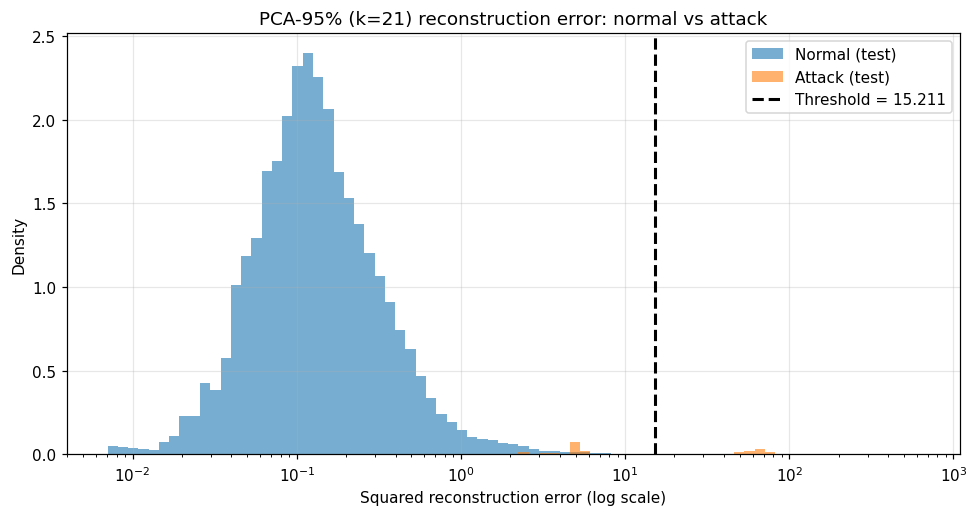

Median error – normal: 0.3489009840444712 | attack: 63.98713990072826


In [15]:
# Reconstruction-error distributions on a log x-axis (tiny floor so zero errors can be drawn)
eps = 1e-6
e = np.maximum(score95, eps)
bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 80)
plt.figure(figsize=(9, 4.8))
plt.hist(e[y_tek == 0], bins=bins, alpha=0.6, density=True, label="Normal (test)")
plt.hist(e[y_tek == 1], bins=bins, alpha=0.6, density=True, label="Attack (test)")
plt.axvline(thr95, c="k", ls="--", lw=2, label=f"Threshold = {thr95:.3f}")
plt.xscale("log"); plt.xlabel("Squared reconstruction error (log scale)"); plt.ylabel("Density")
plt.title(f"PCA-95% (k={k95}) reconstruction error: normal vs attack"); plt.legend(); plt.tight_layout(); plt.show()
print("Median error – normal:", np.median(score95[y_tek == 0]), "| attack:", np.median(score95[y_tek == 1]))
RESULTS["q3b_med"] = [float(np.median(score95[y_tek == 0])), float(np.median(score95[y_tek == 1]))]

**Analysis (b).** After removing the 3 categorical features and duplicate rows, 87,721 normal and 997 attack connections remain (attacks ≈ 1.12%, so the data is highly imbalanced; de-duplication removed most of the repeated attack records). PCA with 95% variance keeps **21 of 38** components. The threshold (15.211) catches **181 of 199 attacks (recall 0.910)** while raising **148 false alarms** on 17,545 normal connections (false-positive rate 0.84%, close to the 1% expected from a 99th-percentile threshold). The histogram shows why it works: the median error is 0.349 for normal traffic but 63.99 for attacks, so most attacks lie far to the right of the threshold. **ROC-AUC = 0.9923** says the error ranks attacks above normals almost perfectly, but **precision is only 0.550** (F1 0.686, AP 0.621): because normals outnumber attacks by about 88 to 1, even a 1% false-alarm rate produces about as many false alarms as true detections.

### (c) Model comparison

,k,Variance kept,Threshold,Precision,Recall,F1,ROC-AUC,AP
Model,,,,,,,,
PCA-2,2,0.3169,271.1323,0.4089,0.6432,0.5000,0.9919,0.6847
PCA-5,5,0.5123,161.6902,0.4730,0.7487,0.5798,0.9924,0.5565
PCA-10,10,0.7063,139.0078,0.4379,0.6382,0.5194,0.9924,0.5989
PCA-20,20,0.9392,18.2327,0.5246,0.9095,0.6654,0.9927,0.6228
PCA-21 (95%),21,0.9524,15.2112,0.5502,0.9095,0.6856,0.9923,0.6205


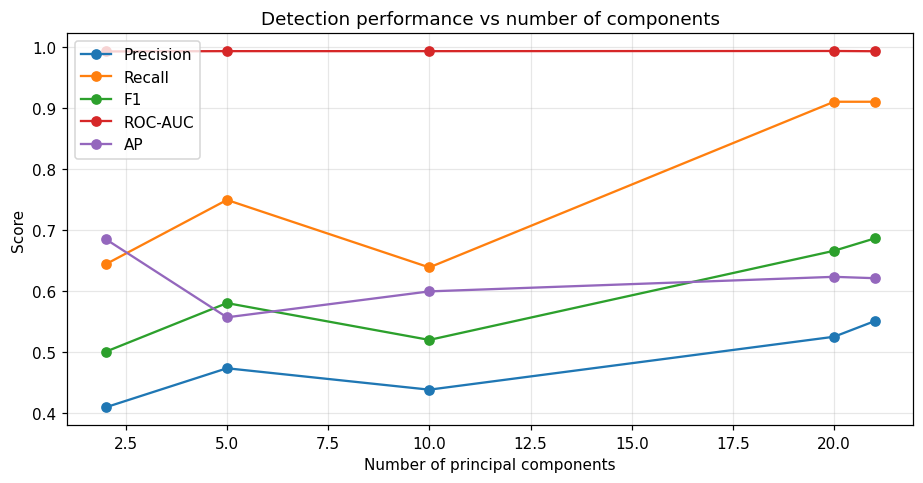

In [16]:
# Same splits and scaler; a separate PCA and threshold for each number of components
rows = []
for k in [2, 5, 10, 20, k95]:
    model = PCA(n_components=k, svd_solver="full").fit(S_tr_norm)
    thr, _, _, m = evaluate(model)
    rows.append({"Model": f"PCA-{k}" + (" (95%)" if k == k95 else ""), "k": k,
                 "Variance kept": model.explained_variance_ratio_.sum(), "Threshold": thr, **m})
cmp_df = pd.DataFrame(rows).set_index("Model"); display(cmp_df)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for col in ["Precision", "Recall", "F1", "ROC-AUC", "AP"]:
    ax.plot(cmp_df["k"], cmp_df[col], "o-", label=col)
ax.set_xlabel("Number of principal components"); ax.set_ylabel("Score")
ax.set_title("Detection performance vs number of components"); ax.legend(); plt.tight_layout(); plt.show()
RESULTS["q3c"] = cmp_df.reset_index().to_dict(orient="records")

**Analysis (c).** ROC-AUC is almost the same for every model (0.9919–0.9927), so the *ranking* of attacks vs normals barely depends on k. The thresholded metrics depend on k strongly. With few components (2, 5, 10) PCA explains only 32–71% of normal-traffic variance, so normal samples themselves have large and widely spread reconstruction errors; the 99th-percentile threshold becomes very high (271 for k=2, 139 for k=10) and many attacks fall below it (recall 0.64–0.75, F1 0.50–0.58). Once k reaches 20–21 (≈94–95% variance), normal traffic is reconstructed well, the threshold drops to about 15, recall rises to 0.91 and F1 to 0.686 (best for the 95% model). The trend is not perfectly monotonic (k=10 is worse than k=5), and AP is actually highest at k=2 (0.685), meaning the very top-scored samples are cleanest there even though the threshold-based detector is weaker. Overall, enough components to describe normal traffic well (≈95% variance) gives the best operating point.

**One limitation:** PCA models normal traffic as a *linear* subspace. An attack whose (log-scaled) features happen to lie close to that subspace is reconstructed well and gets a low score, so it is missed; the 18 missed attacks here are of this kind. Non-linear normal behaviour also cannot be captured, and dropping categorical features (protocol, service, flag) throws away information that could reveal some attacks. A non-linear model (e.g. kernel PCA or an autoencoder) could reduce this.

## Conclusions

- **Q1:** The NumPy PCA matches scikit-learn to floating-point precision (up to eigenvector sign). Scaling is essential for Wine: without it PC1 is just proline (99.8% variance); with it PC1–PC2 explain 55.4% and separate the three cultivars well, driven by flavanoids, proline, colour intensity and alcohol.
- **Q2:** Fashion-MNIST needs 186 of 784 components for 95% variance. An RBF-SVC on the 186-component representation scores 0.8822 accuracy, slightly above raw pixels (0.8754), and is about 5× faster; about 186 components is the recommended setting.
- **Q3:** PCA reconstruction error trained on normal traffic detects intrusions with ROC-AUC ≈ 0.992 and recall 0.91 at a 1% false-alarm target, but precision is limited (0.55) because attacks are rare. Keeping ≈95% of normal variance gives the best F1; too few components inflate normal errors and the threshold.